In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# load the dataset
df = pd.read_csv('HR-Analytics-Employee.csv')

In [4]:
#preview the first 5 rows of the dataset
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [12]:
print(df.shape)
df.info()

(1470, 35)
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null 

In [5]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole      

In [6]:
# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [6]:
print(df.columns.tolist())

['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [7]:
# Check constant columns
constant_cols = df.columns[df.nunique() == 1]
print("\nConstant Columns:", constant_cols.tolist())


Constant Columns: ['EmployeeCount', 'Over18', 'StandardHours']


In [8]:
# Statistical summary of numerical features
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [9]:
# Statistical summary of categorical features
df.describe(include="object").T

C:\Users\h.aldosari\AppData\Local\Temp\ipykernel_21244\3834736808.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object").T


,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


Attrition
No     1233
Yes     237
Name: count, dtype: int64
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


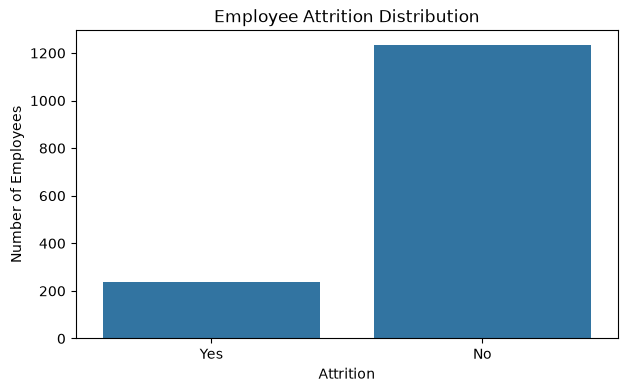

In [13]:

# Check target distribution
print(df["Attrition"].value_counts())

# Calculate percentages
print(df["Attrition"].value_counts(normalize=True) * 100)

# Visualize target distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()


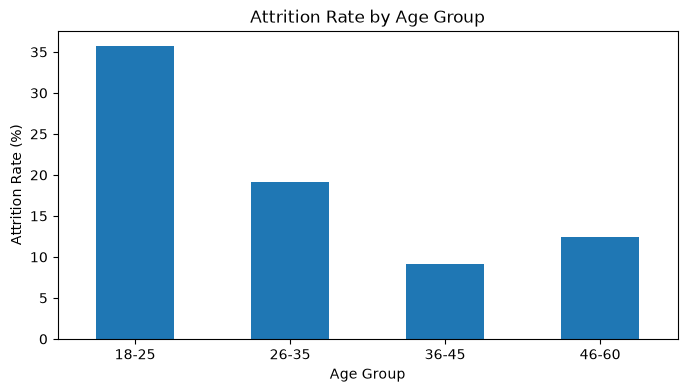

In [ ]:
# Create binary target
df["AttritionFlag"] = (df["Attrition"] == "Yes").astype(int)

# Create age groups
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 60],
    labels=["18-25", "26-35", "36-45", "46-60"]
)

# Calculate attrition rate
age_rate = df.groupby("AgeGroup", observed=True)["AttritionFlag"].mean() * 100

# Visualize
age_rate.plot(kind="bar", figsize=(8, 4))
plt.title("Attrition Rate by Age Group")
plt.ylabel("Attrition Rate (%)")
plt.xlabel("Age Group")
plt.xticks(rotation=0)
plt.show()

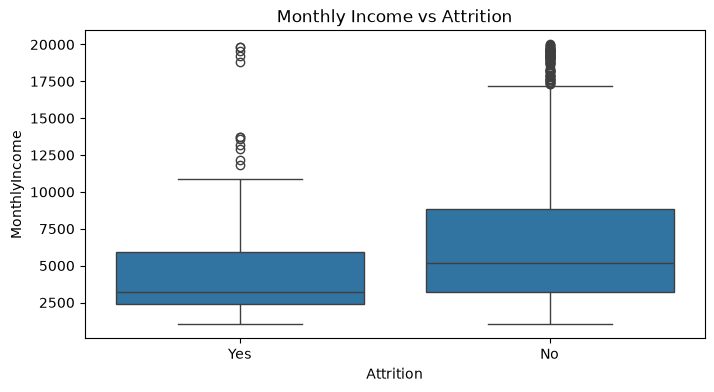

In [18]:

# Compare income by attrition
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome")
plt.title("Monthly Income vs Attrition")
plt.show()


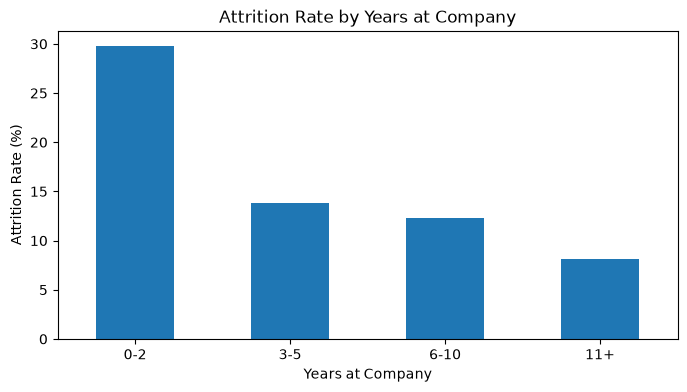

In [19]:

# Create tenure groups
df["TenureGroup"] = pd.cut(
    df["YearsAtCompany"],
    bins=[-1, 2, 5, 10, 40],
    labels=["0-2", "3-5", "6-10", "11+"]
)

# Calculate attrition rate
tenure_rate = df.groupby("TenureGroup", observed=True)["AttritionFlag"].mean() * 100

# Visualize
tenure_rate.plot(kind="bar", figsize=(8, 4))
plt.title("Attrition Rate by Years at Company")
plt.ylabel("Attrition Rate (%)")
plt.xlabel("Years at Company")
plt.xticks(rotation=0)
plt.show()


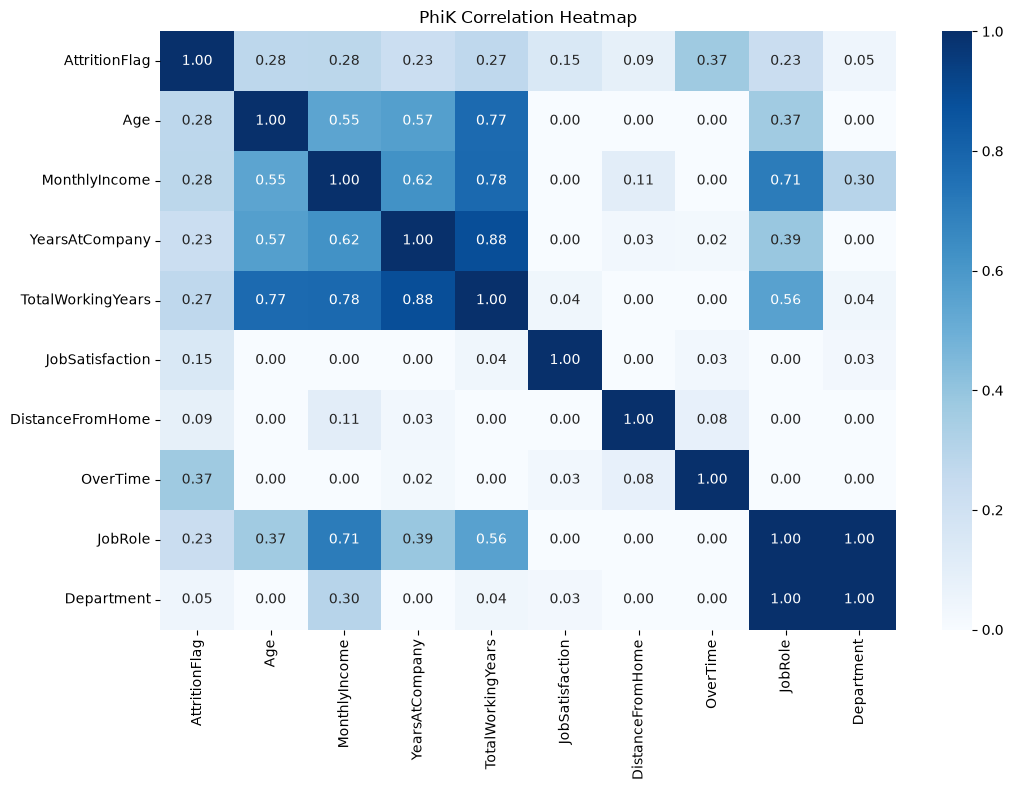

In [21]:

import phik

# Select features for correlation analysis
cols = [
    "AttritionFlag",
    "Age",
    "MonthlyIncome",
    "YearsAtCompany",
    "TotalWorkingYears",
    "JobSatisfaction",
    "DistanceFromHome",
    "OverTime",
    "JobRole",
    "Department"
]

# Identify continuous numerical features
interval_cols = [
    "Age",
    "MonthlyIncome",
    "YearsAtCompany",
    "TotalWorkingYears",
    "DistanceFromHome"
]

# Calculate PhiK correlation
phik_corr = df[cols].phik_matrix(interval_cols=interval_cols)

# Visualize
plt.figure(figsize=(11, 8))
sns.heatmap(
    phik_corr,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    vmin=0,
    vmax=1
)
plt.title("PhiK Correlation Heatmap")
plt.tight_layout()
plt.show()


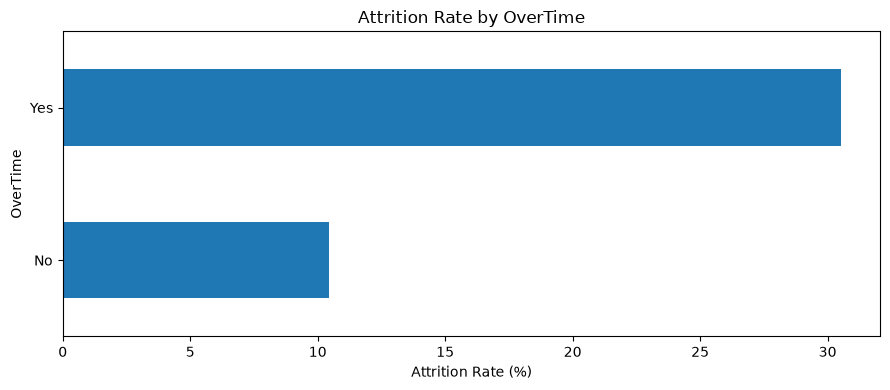

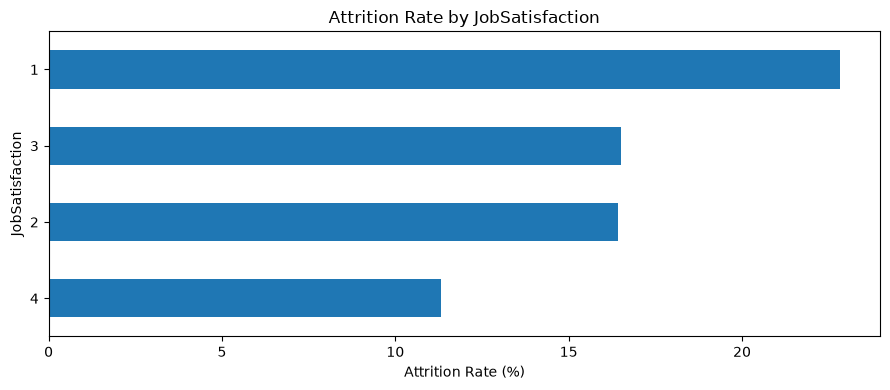

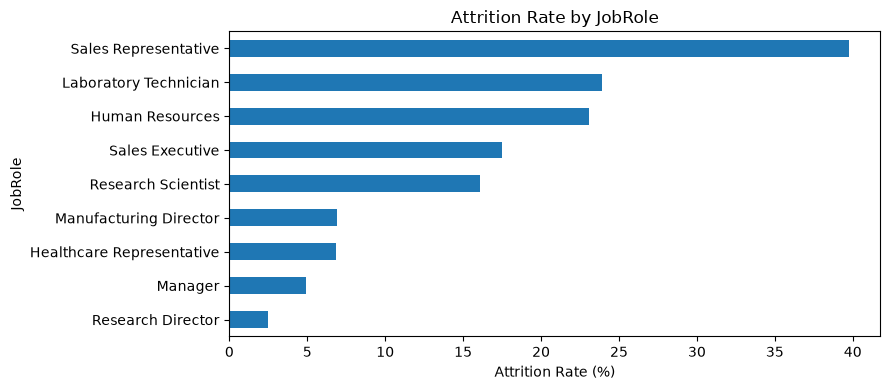

: 

In [ ]:

# Analyze attrition rates by categorical features
features = ["OverTime", "JobSatisfaction", "JobRole"]

for col in features:
    # Calculate attrition rate
    rates = df.groupby(col)["AttritionFlag"].mean() * 100

    # Visualize
    plt.figure(figsize=(9, 4))
    rates.sort_values().plot(kind="barh")
    plt.title(f"Attrition Rate by {col}")
    plt.xlabel("Attrition Rate (%)")
    plt.tight_layout()
    plt.show()
